[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/timecorr/blob/master/docs/tutorial/subjects.ipynb)

# Several subjects

Most studies record several people or several runs. This notebook shows the data formats `timecorr` accepts, the three ways to correlate a list of subjects (`autofc`, `isfc`, `wisfc`), and the functions that combine subjects' results, including a test at each timepoint.

In [1]:
# On Google Colab, install timecorr (this cell does nothing elsewhere).
# If version 0.3.0 is not on PyPI yet, it installs from GitHub instead.
# If Colab asks you to restart the runtime, restart it and run all cells again.
import sys
if "google.colab" in sys.modules:
    !pip install -q "timecorr>=0.3.0" 2>/dev/null || pip install -q "timecorr @ git+https://github.com/ContextLab/timecorr.git@master"

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import timecorr as tc

%matplotlib inline
# one style for every tutorial: colorblind-safe colors (Okabe-Ito)
COLORS = ['#0072B2', '#E69F00', '#009E73', '#D55E00', '#56B4E9', '#CC79A7', '#000000']
plt.rcParams.update({
    'figure.dpi': 100, 'font.size': 11, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.prop_cycle': plt.cycler(color=COLORS), 'legend.frameon': False,
})

## 1. Data formats

Each subject is a timepoints-by-features table: a NumPy array, a pandas DataFrame or a polars DataFrame. A list holds one table per subject, and the formats may be mixed. `tc.format_data` shows what `timecorr` works with: a list of float arrays.

In [3]:
import pandas as pd
import polars as pl

rng = np.random.default_rng(0)
array = rng.standard_normal((200, 4))
frame = pd.DataFrame(array, columns=['a', 'b', 'c', 'd'])
polars_frame = pl.DataFrame(array, schema=['a', 'b', 'c', 'd'])

formatted = tc.format_data([array, frame, polars_frame])
print([type(x).__name__ + str(x.shape) for x in formatted])
same = [np.array_equal(tc.timecorr(x), tc.timecorr(array)) for x in (frame, polars_frame)]
print('pandas and polars give the same result as NumPy:', same)

['ndarray(200, 4)', 'ndarray(200, 4)', 'ndarray(200, 4)']
pandas and polars give the same result as NumPy: [True, True]


## 2. Within or across subjects

With a list, `cfun` chooses what is correlated:

- `tc.autofc`: each subject's own features (within-subject correlations);
- `tc.isfc` (the default): each subject's features with the mean of the other subjects' features (inter-subject functional connectivity, ISFC). It keeps only activity that the subjects share;
- `tc.wisfc`: like `isfc`, with the other subjects weighted by how similar their correlations are.

We simulate two groups of 10 subjects with the same true correlations. In the first, each subject's activity is an independent draw. In the second (`subject_noise=0.5`), the subjects share one draw plus their own noise.

In [4]:
T, K = 300, 8
kernel = {'weights_params': {'var': 100}}
groups = {}
for name, noise in [('independent activity', None), ('shared activity', 0.5)]:
    subjects, corrs = tc.simulate_data(datagen='block', S=10, T=T, K=K, B=3, return_corrs=True,
                                       subject_noise=noise, set_random_seed=2)
    groups[name] = (subjects, corrs[0])

def score(est, truth):
    return np.corrcoef(est[:, K:].ravel(), truth[:, K:].ravel())[0, 1]

cfuns = {'autofc': tc.autofc, 'isfc': tc.isfc, 'wisfc': tc.wisfc}
results = {}
for g, (subjects, truth) in groups.items():
    for c, cfun in cfuns.items():
        results[g, c] = tc.timecorr(subjects, cfun=cfun, combine=tc.corrmean_combine, **kernel)
        print(f'{g:21s} {c:7s} score {score(results[g, c], truth):5.2f}, '
              f'mean |r| {np.abs(results[g, c][:, K:]).mean():.2f}')

independent activity  autofc  score  0.97, mean |r| 0.25
independent activity  isfc    score  0.05, mean |r| 0.05
independent activity  wisfc   score  0.04, mean |r| 0.05
shared activity       autofc  score  0.86, mean |r| 0.21
shared activity       isfc    score  0.86, mean |r| 0.23
shared activity       wisfc   score  0.86, mean |r| 0.23


The score is the correlation between the estimated and true correlations. With independent activity, only `autofc` finds the shared correlations; ISFC is near zero. With shared activity, all three find them.

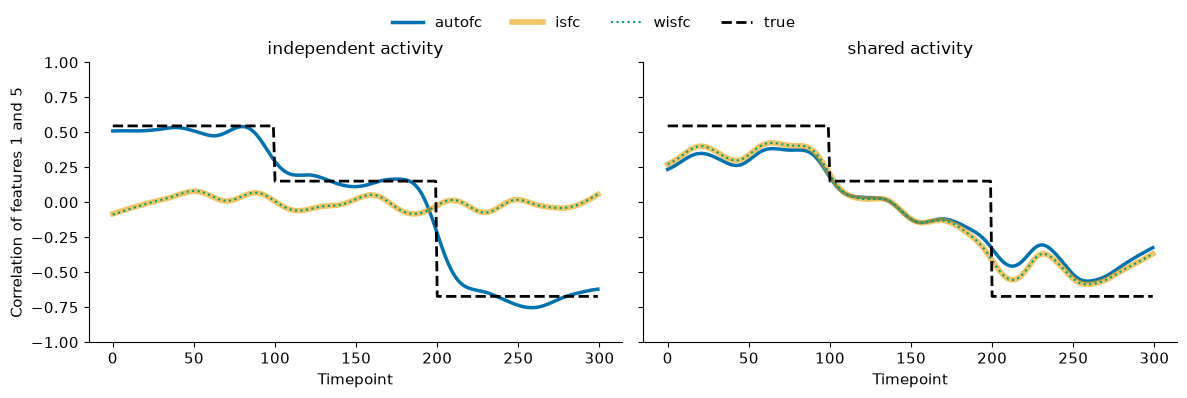

In [5]:
iu = np.triu_indices(K, 1)
truth = groups['shared activity'][1]
pair = np.argmax(np.ptp(tc.vec2mat(truth)[iu[0], iu[1]], axis=1))
i, j = iu[0][pair], iu[1][pair]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, g in zip(axes, groups):
    for c, style in zip(cfuns, [dict(lw=2.5), dict(lw=4, alpha=0.6), dict(lw=1.5, ls=':')]):
        ax.plot(tc.vec2mat(results[g, c])[i, j], label=c, **style)
    ax.plot(tc.vec2mat(groups[g][1])[i, j], color='k', ls='--', lw=2, label='true')
    ax.set(title=g, xlabel='Timepoint', ylim=(-1, 1))
axes[0].set_ylabel(f'Correlation of features {i} and {j}')
fig.legend(*axes[0].get_legend_handles_labels(), loc='upper center', ncol=4,
           bbox_to_anchor=(0.5, 1.06))
fig.tight_layout()
plt.show()

## 3. Combining subjects

`combine` acts on the per-subject results:

- `tc.null_combine` (the default) returns one result per subject;
- `tc.corrmean_combine` averages correlations in Fisher z space (`r2z`, then `z2r` after averaging);
- `tc.mean_combine` takes the plain mean;
- `tc.tstat_combine` gives a one-sample t-test against 0 at every entry (with `return_pvals=True`, also the p-values).

In [6]:
from timecorr.helpers import r2z, z2r

subjects, truth = groups['independent activity']
each = tc.timecorr(subjects, cfun=tc.autofc, **kernel)
print('null_combine:', len(each), 'arrays of', each[0].shape)
for f in (tc.corrmean_combine, tc.mean_combine):
    print(f'{f.__name__}:', tc.timecorr(subjects, cfun=tc.autofc, combine=f, **kernel).shape)

by_hand = z2r(np.mean([r2z(x) for x in each], axis=0))
print('corrmean_combine equals z2r(mean(r2z)):', np.allclose(tc.corrmean_combine(each), by_hand))
t_stat, p = tc.tstat_combine(each, return_pvals=True)
print('tstat_combine: t', t_stat.shape, ', p', p.shape)

null_combine: 10 arrays of (300, 36)
corrmean_combine: (300, 36)
mean_combine: (300, 36)
corrmean_combine equals z2r(mean(r2z)): True
tstat_combine: t (300, 36) , p (300, 36)


The t-test at each timepoint asks whether a correlation differs from zero across subjects. We correct for the number of timepoints (Bonferroni). Neighboring timepoints share most of their kernel weights, so their tests are not independent and the correction is conservative.

timepoints with corrected p < 0.05: 196 of 300


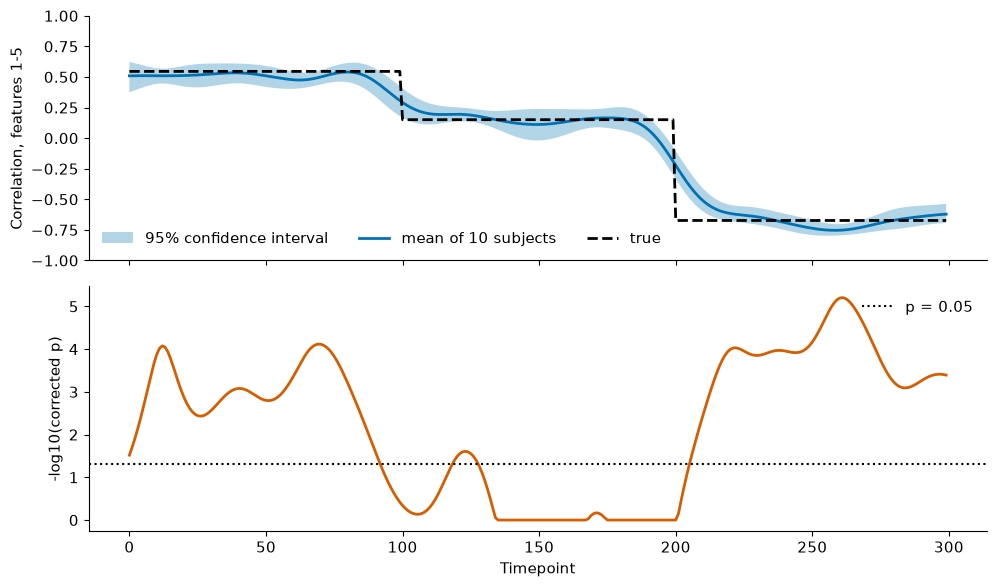

In [7]:
col = K + pair  # column of the pair (i, j) in the vectorized output
p_bonf = np.minimum(p[:, col] * T, 1)
print(f'timepoints with corrected p < 0.05: {(p_bonf < 0.05).sum()} of {T}')

z = np.array([r2z(x[:, col]) for x in each])
sem = z.std(0, ddof=1) / np.sqrt(len(z))
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].fill_between(np.arange(T), z2r(z.mean(0) - 1.96 * sem), z2r(z.mean(0) + 1.96 * sem),
                     alpha=0.3, label='95% confidence interval')
axes[0].plot(z2r(z.mean(0)), lw=2, label='mean of 10 subjects')
axes[0].plot(tc.vec2mat(truth)[i, j], color='k', ls='--', lw=2, label='true')
axes[0].set(ylabel=f'Correlation, features {i}-{j}', ylim=(-1, 1))
axes[0].legend(loc='lower left', ncol=3)
axes[1].plot(-np.log10(p_bonf), color=COLORS[3], lw=2)
axes[1].axhline(-np.log10(0.05), color='k', ls=':', label='p = 0.05')
axes[1].set(xlabel='Timepoint', ylabel='-log10(corrected p)')
axes[1].legend(loc='upper right')
fig.tight_layout()
plt.show()

Next: [reducing the number of features](reduce.ipynb).